<a href="https://colab.research.google.com/github/marcosfelipp/aulas-neuro-ai/blob/main/aula-14-15-perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> &nbsp; <a href="https://kaggle.com/kernels/welcome?src=https://raw.githubusercontent.com/marcosfelipp/aulas-neuro-ai/main/aula-14-15-perceptron.ipynb" target="_parent"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open in Kaggle"/></a>

# Aulas 14 e 15 · O perceptron

Duas aulas para construir, do zero, a menor coisa que **aprende**: um neurônio artificial.

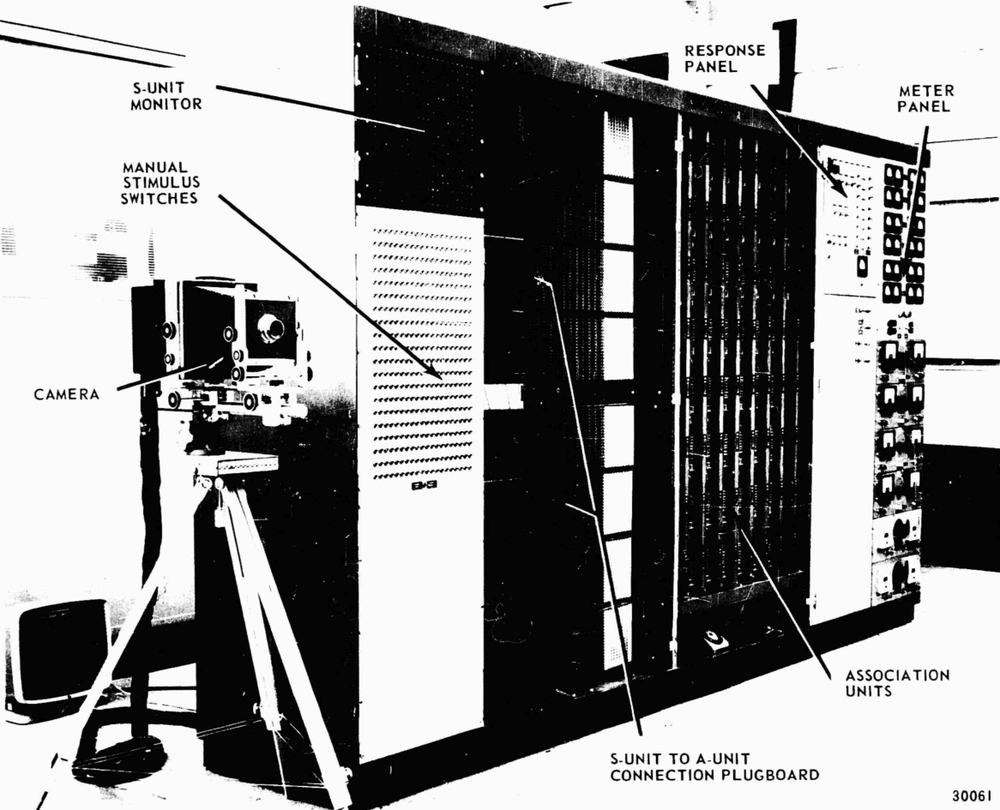

<small>Mark I Perceptron, construído por Frank Rosenblatt no Cornell Aeronautical Laboratory.
Figura 2 do <i>Mark I Perceptron Operators' Manual</i> (Hay &amp; Murray, 1960) — domínio público.</small>

Isto é um perceptron. Não é metáfora: é a máquina, de 1958, do tamanho de um armário.

Ela aprendia a distinguir um cartão marcado à esquerda de um marcado à direita. O *New York
Times* escreveu, em 1958, que a Marinha esperava dali uma máquina capaz de "andar, falar, ver,
escrever, se reproduzir e ter consciência da própria existência".

Nas próximas duas aulas você vai escrever essa máquina em três funções. Os potenciômetros vão
ser um `np.zeros`.

---
· O neurônio que decide
---

## 1 · De onde vem a ideia

Um neurônio recebe sinais de vários outros. Cada conexão tem uma **força** diferente: algumas
excitam, outras inibem. O corpo celular soma tudo o que chegou e, se o total passar de um
certo ponto, ele dispara. Se não passar, fica quieto.

O perceptron é essa frase escrita em três linhas de código:



Três nomes para guardar:

- **entrada** (`x`) — o que chega. Aqui vão ser medidas de um paciente.
- **peso** (`w`) — o quanto cada entrada conta. Peso negativo inibe.
- **viés** — o quanto o neurônio já pende para um lado antes de receber qualquer coisa. É o
  limiar disfarçado de parcela da soma.

## 2 · A conta



Só isso. Uma multiplicação por entrada, uma soma, e uma comparação com zero.


## 3 · Implementação · `soma_ponderada`

Escreva a função que faz a conta da figura: multiplica cada entrada pelo seu peso, soma tudo,
e acrescenta o viés no fim.

`pesos` e `entrada` são arrays do mesmo tamanho. Use um laço — um passo por característica.

In [ ]:
def soma_ponderada(pesos, vies, entrada):
    """Multiplica cada entrada pelo seu peso, soma tudo e acrescenta o viés."""

In [ ]:
import numpy as np

p = np.array([0.2, 0.1])

assert round(soma_ponderada(p, -0.2, np.array([0.0, 0.0])), 4) == -0.2
assert round(soma_ponderada(p, -0.2, np.array([1.0, 0.0])), 4) == 0.0
assert round(soma_ponderada(p, -0.2, np.array([0.0, 1.0])), 4) == -0.1
assert round(soma_ponderada(p, -0.2, np.array([1.0, 1.0])), 4) == 0.1

print("ok")

## 4 · Implementação · `prever`

Agora a decisão: devolve `1` se a soma ponderada passar de zero, e `0` se não passar.

Repare no segundo `assert`: quando `z` dá exatamente zero, a resposta é `0` — porque `> 0`
deixa o próprio zero de fora. É a mesma pegadinha do `10 > 10` da aula 13.

In [ ]:
def prever(pesos, vies, entrada):
    """Devolve 1 se a soma ponderada for maior que zero, senão 0."""

In [ ]:
assert prever(p, -0.2, np.array([0.0, 0.0])) == 0
assert prever(p, -0.2, np.array([1.0, 0.0])) == 0
assert prever(p, -0.2, np.array([0.0, 1.0])) == 0
assert prever(p, -0.2, np.array([1.0, 1.0])) == 1

print("ok")

## 5 · O neurônio inteiro, com pesos escolhidos à mão

Os quatro pontos abaixo são a porta lógica **AND**: a resposta só é 1 quando as duas entradas
são 1. É um problema minúsculo de propósito — você confere o resultado de cabeça.

Escreva um laço que, para cada linha de `X`, imprima a entrada, o que o neurônio previu e a
resposta certa. Compare com a tabela que você preencheu lá em cima.

In [ ]:
X = np.array([[0.0, 0.0],
              [0.0, 1.0],
              [1.0, 0.0],
              [1.0, 1.0]])
y = np.array([0, 0, 0, 1])

pesos = np.array([0.2, 0.1])
vies = -0.2

# escreva o laço aqui

## 6 · O que os pesos realmente são

Dois pesos e um viés desenham **uma reta**. De um lado da reta o neurônio responde 1, do
outro responde 0. Treinar é procurar essa reta.




---
· O neurônio que aprende
---

## 7 · Como ele corrige

O neurônio chuta, olha a resposta certa e se ajusta. O ajuste cabe numa ideia só:

```
erro = resposta_certa - resposta_do_neuronio
```

Como os dois lados só podem ser 0 ou 1, **o erro só pode valer três coisas**:

| erro | o que aconteceu | o que fazer |
|---|---|---|
| `0` | acertou | nada |
| `+1` | devia dar 1 e deu 0 | **aumentar** a soma |
| `-1` | devia dar 0 e deu 1 | **diminuir** a soma |

E como se aumenta a soma? Somando um pouco de cada entrada ao seu peso:

```
peso_novo = peso + taxa * erro * entrada
```

Leia devagar, porque a linha é mais esperta do que parece:

- se `erro` é `0`, nada muda — **o perceptron só aprende quando erra**;
- o sinal do `erro` decide se o peso sobe ou desce;
- multiplicar por `entrada` faz com que **só os pesos das entradas que estavam ativas** mudem.
  Entrada zero, peso intocado. Quem não participou do erro não é culpado por ele;
- `taxa` é o tamanho do passo.

O viés se ajusta igual, só que sem a entrada: `vies = vies + taxa * erro`.

**Época** é uma passada completa por todos os exemplos. O treino repete épocas até parar de
errar.

## 8 · Implementação · `treinar`

1. comece com todos os pesos em zero (`np.zeros`) e o viés em `0.0`;
2. repita por `epocas` vezes;
3. em cada época, passe por **todas as linhas** de `X`;
4. para cada linha, calcule o erro e, **se ele não for zero**, ajuste cada peso e o viés;
5. conte quantos erros aconteceram na época e guarde esse número numa lista;
6. devolva os pesos, o viés e a lista.

`X.shape[0]` é o número de linhas e `X.shape[1]` o número de colunas — a vírgula da aula 11.

In [ ]:
def treinar(X, y, taxa, epocas):
    """Ajusta pesos e viés para acertar y a partir de X.

    Devolve (pesos, vies, historico), onde historico[e] é quantos
    erros aconteceram na época e.
    """

In [ ]:
def acertos(pesos, vies, X, y):
    """Quantas linhas de X o neurônio classifica certo. (pronta, não precisa escrever)"""
    n = 0
    for i in range(X.shape[0]):
        if prever(pesos, vies, X[i]) == y[i]:
            n = n + 1
    return n


pesos, vies, historico = treinar(X, y, 0.1, 10)

assert len(historico) == 10
assert historico[-1] == 0                       # no fim, não erra mais
assert acertos(pesos, vies, X, y) == 4          # acerta os quatro pontos

print("ok")
print("pesos:", pesos, " vies:", round(vies, 4))
print("historico:", historico)

## 9 · Ler o histórico

Olhe a lista que saiu. Ela é a aula inteira num lugar só: o neurônio erra, erra mais, erra
menos, e em algum momento **para de errar**.

Três perguntas:

1. em que época ele parou de errar?
2. por que o número de erros **sobe** antes de cair?
3. o que acontece se você treinar com `epocas=3`? Tente.

## 10 · Um problema de verdade

Dez pacientes. Duas medidas de cada um: o PHQ-9 na primeira consulta e há quantas semanas os
sintomas começaram. A resposta é se ele respondeu ou não ao tratamento.

Treine o mesmo neurônio nesses dados, veja quantos ele acerta, e classifique o paciente novo.

In [ ]:
C = np.array([[ 8.0,  2.0],
              [10.0,  4.0],
              [12.0,  3.0],
              [ 9.0,  6.0],
              [14.0,  5.0],
              [22.0, 30.0],
              [25.0, 24.0],
              [20.0, 40.0],
              [24.0, 36.0],
              [27.0, 28.0]])
resposta = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0])

novo = np.array([11.0, 5.0])

# treine, meça os acertos e classifique `novo`

### Um aviso que vale a aula inteira

Olhe os pesos que saíram. O peso do **PHQ-9 inicial ficou positivo** — como se escore mais
alto ajudasse a responder ao tratamento. Os dados dizem o contrário.

Não é um bug. É que as semanas de sintoma sozinhas já separam os dois grupos, e **o
perceptron para na primeira reta que funciona, não na melhor**. Qualquer reta que separe
serve para ele.

Isso tem uma consequência prática: **peso de perceptron não é tamanho de efeito.** Ler os
pesos como se fossem coeficientes clínicos é um erro, e é um erro fácil de cometer.

Consertar isso — procurar a *melhor* reta, e não qualquer uma — é o que inventou a função de
perda e a descida de gradiente, que é para onde o curso vai.

## 11 · Onde ele falha

Os mesmos quatro pontos do AND, com uma resposta diferente: 1 quando as entradas são
**diferentes** uma da outra. É a porta XOR.

Treine por 20 épocas e olhe o histórico.

In [ ]:
y_xor = np.array([0, 1, 1, 0])

# treine com X e y_xor, imprima o historico e os acertos

O histórico trava e nunca chega a zero. Aumentar as épocas não resolve, mudar a taxa não
resolve. O motivo é geométrico:



Um neurônio é **uma reta**. Não existe reta que separe esses quatro pontos — então não existe
perceptron que resolva o XOR. Isso foi demonstrado em 1969 e congelou a área por quase vinte
anos.

A saída foi empilhar neurônios em camadas: a primeira camada dobra o espaço, a segunda separa
o que ficou dobrado. É a rede neural, e é o assunto das aulas 25 a 28.

## 12 · Fecho

Você escreveu três funções. A do meio, `soma_ponderada`, tem um laço que o NumPy faz numa
linha só:

```python
total = 0.0
for j in range(pesos.size):
    total = total + pesos[j] * entrada[j]
```

vira

```python
pesos @ entrada
```

O `@` é só isso: a abreviação do laço que você acabou de escrever. Quando ele aparecer no
PyTorch — e vai aparecer em toda linha — você já sabe o que tem dentro.

### Sem olhar para cima

Numa célula em branco, reescreva a função `prever` do zero. Sem rolar a tela.